# India Air Quality (AQI) Collector

**Pipeline:** OpenAQ API → pandas (clean · convert units · flag) → PostgreSQL (`aqi_db`) → SQL views → reports


## 1 · Configuration

In [16]:
import os, time, warnings
from decimal import Decimal
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import requests
import psycopg2
from psycopg2.extras import execute_values
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)

# ---- PostgreSQL (pgAdmin's server) ----------------------------------------
DB = dict(
    host=os.getenv("PGHOST", "localhost"),
    port=int(os.getenv("PGPORT", 5432)),
    dbname=os.getenv("PGDATABASE", "aqi_db"),
    user=os.getenv("PGUSER", "postgres"),
    password="admin123",
)

# ---- OpenAQ ----------------------------------------------------------------
OPENAQ_API_KEY = "2c068e22cf43654b18a00dd4089da75888d8ca29a85f36eb467cf2b6f25d5294"
OPENAQ_BASE    = "https://api.openaq.org/v3"

LOOKBACK_HOURS        = 48     # hourly runs: 48 is plenty (overlap is harmless).  First run / backfill: e.g. 24*90
MAX_STATIONS_PER_CITY = 3     # fewer stations = far fewer API calls (each station has up to 6 pollutant sensors)
MAX_STALE_DAYS        = 7      # skip stations whose newest reading is older than this (many OpenAQ stations are dead)
CITIES_TO_RUN         = ["Delhi", "Mumbai"]   # quick test first! Set to None to run all cities
SEARCH_RADIUS_M       = 25_000 # OpenAQ maximum

# ---- Cleaning rules --------------------------------------------------------
PARAMS         = ["pm25", "pm10", "no2", "so2", "co", "o3"]
MAX_GAP_HOURS  = 3             # gaps up to this long are linearly interpolated, longer ones stay missing
SENTINELS      = {-999, -9999, 9999, 999999}
# Plausibility ceilings AFTER unit conversion (ug/m3; CO in mg/m3). Above => sensor error.
VALID_MAX      = {"pm25": 1500, "pm10": 3000, "no2": 2000, "so2": 3000, "co": 100, "o3": 1000}
# Start of CPCB "Poor" band (AQI > 200). Reading above this => flagged unhealthy.
UNHEALTHY_ABOVE = {"pm25": 90, "pm10": 250, "no2": 180, "so2": 380, "co": 10, "o3": 168}
# Molecular weights (g/mol) for ppb/ppm -> ug/m3 conversion
MW = {"no2": 46.01, "so2": 64.07, "o3": 48.00, "co": 28.01}
# CO sanity check: real ambient CO in ug/m3 is hundreds-to-thousands. A feed that says "ug/m3" but whose typical
# value is below this is almost certainly already in mg/m3 (mislabelled) and must NOT be divided by 1000.
CO_UGM3_MIN = 20
CO_FIXES = []     # filled by transform(): one entry per station whose CO unit label was corrected

if not OPENAQ_API_KEY:
    raise RuntimeError("OPENAQ_API_KEY is not set. Get a free key at https://explore.openaq.org/register, "
                       "then set it (see README) or paste it into this cell, and re-run.")
print("OpenAQ key found - live mode")

OpenAQ key found - live mode


## 2 · Database helpers & city list


In [17]:
def get_conn():
    return psycopg2.connect(**DB)

def query_df(sql, params=None):
    with get_conn() as conn, conn.cursor() as cur:
        cur.execute(sql, params)
        cols = [d[0] for d in cur.description]
        df = pd.DataFrame(cur.fetchall(), columns=cols)
    for c in df.columns:                      # PostgreSQL NUMERIC arrives as Decimal -> convert to plain floats
        if df[c].map(lambda v: isinstance(v, Decimal)).any():
            df[c] = df[c].astype(float)
    return df

cities = query_df("SELECT city_id, city_name, state, latitude::float AS latitude, longitude::float AS longitude "
                  "FROM aqi.cities WHERE is_active ORDER BY city_id")
cities

,city_id,city_name,state,latitude,longitude
0,1,Delhi,Delhi,28.6139,77.2090
1,2,Mumbai,Maharashtra,19.0760,72.8777
2,3,Kolkata,West Bengal,22.5726,88.3639
3,4,Chennai,Tamil Nadu,13.0827,80.2707
4,5,Bengaluru,Karnataka,12.9716,77.5946
5,6,Hyderabad,Telangana,17.3850,78.4867
6,7,Ahmedabad,Gujarat,23.0225,72.5714
7,8,Pune,Maharashtra,18.5204,73.8567
8,9,Lucknow,Uttar Pradesh,26.8467,80.9462
9,10,Patna,Bihar,25.5941,85.1376


## 3 · Extract — OpenAQ v3
For every city: find stations within 25 km of the centre → list their pollutant sensors → pull hourly aggregates (`/sensors/{id}/hours`).
Handles pagination, rate limiting (HTTP 429 + `Retry-After`) and transient 5xx errors.

In [18]:
session = requests.Session()
session.headers.update({"X-API-Key": OPENAQ_API_KEY, "Accept": "application/json"})

def api_get(path, params=None, retries=6):
    for attempt in range(retries):
        r = session.get(OPENAQ_BASE + path, params=params, timeout=45)
        if r.status_code == 429:                                   # rate-limited: wait until the window resets
            wait = float(r.headers.get("x-ratelimit-reset", r.headers.get("Retry-After", 2 ** attempt))) + 1
            print(f"   rate limit hit - waiting {wait:.0f}s ...", flush=True)
            time.sleep(wait); continue
        if r.status_code >= 500:                                   # transient server error
            time.sleep(2 ** attempt); continue
        r.raise_for_status()
        if r.headers.get("x-ratelimit-remaining", "99").isdigit() and int(r.headers["x-ratelimit-remaining"]) <= 1:
            time.sleep(float(r.headers.get("x-ratelimit-reset", 5)) + 1)   # pause BEFORE hitting the limit
        else:
            time.sleep(0.1)
        return r.json()
    raise RuntimeError(f"OpenAQ request failed after {retries} tries: {path}")

def _utc(d):
    try:
        return pd.Timestamp(d["utc"]) if d and d.get("utc") else None
    except Exception:
        return None

def find_stations(lat, lon):
    # stations within the search radius that still report (newest reading within MAX_STALE_DAYS)
    data = api_get("/locations", {"coordinates": f"{lat},{lon}", "radius": SEARCH_RADIUS_M, "limit": 1000})
    now, epoch = pd.Timestamp.now(tz="UTC"), pd.Timestamp("1970-01-01", tz="UTC")
    out, stale = [], 0
    for loc in data.get("results", []):
        sensors = [{"sensor_id": s["id"], "parameter": s["parameter"]["name"].lower()}
                   for s in loc.get("sensors", []) if s["parameter"]["name"].lower() in PARAMS]
        if not sensors:
            continue
        last = _utc(loc.get("datetimeLast"))
        if last is not None and (now - last) > pd.Timedelta(days=MAX_STALE_DAYS):
            stale += 1
            continue
        coords = loc.get("coordinates") or {}
        out.append({"station_id": loc["id"], "station_name": loc.get("name"),
                    "latitude": coords.get("latitude"), "longitude": coords.get("longitude"),
                    "provider": (loc.get("provider") or {}).get("name"), "sensors": sensors, "last_utc": last})
    # best first: has PM2.5, most recently active, most pollutants
    out.sort(key=lambda s: ("pm25" in {x["parameter"] for x in s["sensors"]}, s["last_utc"] or epoch, len(s["sensors"])),
             reverse=True)
    return out[:MAX_STATIONS_PER_CITY], stale

_debug_shown = {"done": False}
def fetch_sensor_hours(sensor_id, start, end):
    rows, page = [], 1
    while True:
        data = api_get(f"/sensors/{sensor_id}/hours", {
            "datetime_from": start.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "datetime_to":   end.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "limit": 1000, "page": page})
        res = data.get("results", [])
        if page == 1 and not res and not _debug_shown["done"]:      # show ONE raw empty reply to help debugging
            _debug_shown["done"] = True
            print(f"   (debug) empty reply for sensor {sensor_id}, window {start:%Y-%m-%d %H:%M} -> {end:%Y-%m-%d %H:%M}: {str(data)[:300]}", flush=True)
        for x in res:
            rows.append({"ts_utc": x["period"]["datetimeFrom"]["utc"],
                         "value": x.get("value"),
                         "unit": x["parameter"].get("units")})
        if len(res) < 1000:
            break
        page += 1
    return rows

def fetch_city_live(city, start, end):
    stations, stale = find_stations(city.latitude, city.longitude)
    n_sensors = sum(len(x["sensors"]) for x in stations)
    print(f"   {city.city_name}: using {len(stations)} active stations ({n_sensors} sensors); skipped {stale} stale stations", flush=True)
    span = end - start
    frames = []
    for st in stations:
        # window is anchored on the station's own newest reading, so a slightly delayed station still returns data
        st_end = min(end, st["last_utc"]) if st["last_utc"] is not None else end
        st_start = st_end - span
        for sn in st["sensors"]:
            rows = fetch_sensor_hours(sn["sensor_id"], st_start, st_end)
            print(f"     station {st['station_id']} {sn['parameter']:<5} -> {len(rows)} rows", flush=True)
            if rows:
                df = pd.DataFrame(rows)
                df["station_id"], df["parameter"] = st["station_id"], sn["parameter"]
                frames.append(df)
    raw = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(
        columns=["ts_utc", "value", "unit", "station_id", "parameter"])
    return raw, stations

## 4 · Transform


In [19]:
# CO sanity check settings: urban India CO is ~0.1-3 mg/m3. If the feed's unit label would give a typical value below
# CO_MIN_MGM3 while the raw numbers look like mg/m3 (0.05-30), the label is wrong and the raw numbers are used as mg/m3.
CO_MIN_MGM3 = 0.02
CO_FIXES = []

def norm_unit(u):
    u = (u or "").lower().replace("µ", "u").replace("μ", "u").replace("³", "3").replace(" ", "")
    return u

def unit_factor(param, unit):
    # multiplier converting `unit` to the standard unit (ug/m3; CO mg/m3); NaN if the unit is unknown
    u = norm_unit(unit)
    if param in ("pm25", "pm10"):
        return 1.0 if u == "ug/m3" else np.nan
    ppb_to_ug = MW[param] / 24.45                      # 25 C, 1 atm
    if param == "co":                                  # target: mg/m3
        return {"mg/m3": 1.0, "ug/m3": 1e-3, "ppm": ppb_to_ug, "ppb": ppb_to_ug * 1e-3}.get(u, np.nan)
    return {"ug/m3": 1.0, "ppb": ppb_to_ug, "ppm": ppb_to_ug * 1e3, "mg/m3": 1e3}.get(u, np.nan)

def convert_series(param, values, units):
    factors = units.map(lambda u: unit_factor(param, u))
    return values * factors

def _fill_short_gaps(s, max_gap):
    # interpolate only NaN runs of <= max_gap hours (and only between valid points)
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    filled = s.interpolate(method="time", limit_area="inside")
    return s.where(~(isna & (run_len <= max_gap)), filled)

def transform(raw, max_gap=MAX_GAP_HOURS):
    stats = dict(fetched=len(raw), invalid=0, missing=0, imputed=0, loaded=0, unhealthy=0)
    if raw.empty:
        return pd.DataFrame(), stats
    df = raw.copy()
    df["ts_utc"] = pd.to_datetime(df["ts_utc"], utc=True).dt.floor("h")
    df["value"]  = pd.to_numeric(df["value"], errors="coerce")
    df["unit"]   = df["unit"].map(norm_unit)

    # --- units ---
    df["value_std"] = np.nan
    for p, g in df.groupby("parameter"):
        df.loc[g.index, "value_std"] = convert_series(p, g["value"], g["unit"])

    # --- CO sanity check: some feeds mislabel mg/m3 values as ppb / ug/m3 ---
    is_co = df["parameter"] == "co"
    for (sid, u), g in df[is_co].groupby(["station_id", "unit"]):
        ok = g["value"] >= 0
        raw_med, std_med = g.loc[ok, "value"].median(), g.loc[ok, "value_std"].median()
        if pd.notna(raw_med) and pd.notna(std_med) and std_med < CO_MIN_MGM3 and 0.05 <= raw_med <= 30:
            df.loc[g.index, "value_std"] = g["value"]            # raw numbers are already mg/m3
            CO_FIXES.append({"station_id": sid, "labelled_unit": u, "raw_median": round(float(raw_med), 3)})
            print(f"   ⚠ CO unit fix: station {sid} labelled '{u}' but values (median {raw_med:.2f}) would be impossibly low "
                  f"-> treated as mg/m3", flush=True)

    # --- invalid -> NaN (counted) ---
    had_value = df["value"].notna()
    bad = had_value & (df["value"].isin(SENTINELS) | (df["value"] < 0) | df["value_std"].isna()
                       | (df["value_std"] > df["parameter"].map(VALID_MAX)))
    stats["invalid"] = int(bad.sum())
    df.loc[bad, "value_std"] = np.nan

    # --- duplicates (same station/pollutant/hour) -> mean ---
    df = (df.groupby(["station_id", "parameter", "ts_utc"], as_index=False)["value_std"].mean())

    # --- rebuild a complete hourly grid per series, fill short gaps ---
    parts = []
    for (sid, p), g in df.groupby(["station_id", "parameter"]):
        s = g.set_index("ts_utc")["value_std"].sort_index()
        grid = pd.date_range(s.index.min(), s.index.max(), freq="h", tz="UTC")
        s = s.reindex(grid)
        filled = _fill_short_gaps(s, max_gap)
        out = pd.DataFrame({"station_id": sid, "parameter": p, "ts_utc": grid, "value": filled.values,
                            "is_imputed": (s.isna() & filled.notna()).values})
        parts.append(out)
    clean = pd.concat(parts, ignore_index=True)

    stats["missing"] = int(clean["value"].isna().sum())
    stats["imputed"] = int(clean["is_imputed"].sum())
    clean = clean.dropna(subset=["value"]).copy()

    # --- final shape + unhealthy flag ---
    clean["value"] = clean["value"].round(3)
    clean["unit"] = np.where(clean["parameter"] == "co", "mg/m3", "ug/m3")
    clean["is_unhealthy"] = clean["value"] > clean["parameter"].map(UNHEALTHY_ABOVE)
    stats["loaded"], stats["unhealthy"] = len(clean), int(clean["is_unhealthy"].sum())
    return clean, stats

### Unit-test the cleaning rules (runs instantly, no database or API needed)

In [20]:
_t = pd.DataFrame({
    "ts_utc": pd.date_range("2026-01-01", periods=10, freq="h", tz="UTC").tolist() * 1,
    "value": [10, 20, np.nan, np.nan, 50, 60, -999, np.nan, np.nan, np.nan], "unit": "µg/m³",
    "station_id": 1, "parameter": "pm25"})
_t = _t.drop(index=[9])                                       # hour 9 absent entirely
_c, _s = transform(_t)
assert _s["invalid"] == 1, _s                                 # the -999
assert _c.loc[_c.ts_utc.dt.hour == 2, "value"].iloc[0] == 30  # 2h gap interpolated
assert _c.loc[_c.ts_utc.dt.hour == 2, "is_imputed"].iloc[0]
assert 6 not in _c.ts_utc.dt.hour.values and 7 not in _c.ts_utc.dt.hour.values   # trailing gap stays empty

# unit conversion: 100 ppb NO2 = 100*46.01/24.45 ug/m3 ; 1 ppm CO = 28.01/24.45 mg/m3
_u = pd.DataFrame({"ts_utc": [pd.Timestamp("2026-01-01", tz="UTC")] * 2, "value": [100.0, 1.0],
                   "unit": ["ppb", "ppm"], "station_id": [1, 1], "parameter": ["no2", "co"]})
_cu, _ = transform(_u)
assert abs(_cu.set_index("parameter").loc["no2", "value"] - 188.17) < 0.1
assert abs(_cu.set_index("parameter").loc["co", "value"] - 1.146) < 0.01

# unhealthy flag: PM2.5 95 > 90 -> True ; 85 -> False
_f, _ = transform(pd.DataFrame({"ts_utc": pd.date_range("2026-01-01", periods=2, freq="h", tz="UTC"),
                                "value": [95.0, 85.0], "unit": "ug/m3", "station_id": 1, "parameter": "pm25"}))
assert _f["is_unhealthy"].tolist() == [True, False]
# CO unit-label check: values ~0.5 labelled ug/m3 are really mg/m3 (keep 0.5); values ~500 ug/m3 are real (-> 0.5 mg/m3)
_h = pd.date_range("2026-01-01", periods=3, freq="h", tz="UTC")
_co_bad, _ = transform(pd.DataFrame({"ts_utc": _h, "value": [0.4, 0.5, 0.6], "unit": "µg/m³", "station_id": 7, "parameter": "co"}))
_co_ok,  _ = transform(pd.DataFrame({"ts_utc": _h, "value": [400.0, 500.0, 600.0], "unit": "µg/m³", "station_id": 8, "parameter": "co"}))
assert abs(_co_bad["value"].median() - 0.5) < 1e-6, _co_bad
assert abs(_co_ok["value"].median() - 0.5) < 1e-6, _co_ok
CO_FIXES.clear()
print(" transform unit tests passed")

   ⚠ CO unit fix: station 7 labelled 'ug/m3' but values (median 0.50) would be impossibly low -> treated as mg/m3
 transform unit tests passed


## 5 · Load — upsert into PostgreSQL

In [21]:
def upsert_stations(cur, city_id, stations):
    execute_values(cur, """
        INSERT INTO aqi.stations (station_id, city_id, station_name, latitude, longitude, provider)
        VALUES %s
        ON CONFLICT (station_id) DO UPDATE
           SET station_name = EXCLUDED.station_name, latitude = EXCLUDED.latitude,
               longitude = EXCLUDED.longitude, provider = EXCLUDED.provider""",
        [(s["station_id"], int(city_id), s["station_name"], s["latitude"], s["longitude"], s["provider"])
         for s in stations])

def upsert_readings(cur, df, source):
    rows = [(int(r.station_id), r.parameter, r.ts_utc.to_pydatetime(), float(r.value), r.unit,
             bool(r.is_imputed), bool(r.is_unhealthy), source)
            for r in df.itertuples(index=False)]
    execute_values(cur, """
        INSERT INTO aqi.readings_hourly
              (station_id, parameter, ts_utc, value, unit, is_imputed, is_unhealthy, source)
        VALUES %s
        ON CONFLICT (station_id, parameter, ts_utc) DO UPDATE
           SET value = EXCLUDED.value, unit = EXCLUDED.unit, is_imputed = EXCLUDED.is_imputed,
               is_unhealthy = EXCLUDED.is_unhealthy, source = EXCLUDED.source, ingested_at = now()""",
        rows, page_size=5000)

def log_run(cur, city_name, source, st):
    cur.execute("""INSERT INTO aqi.ingest_log
        (city_name, source, rows_fetched, rows_invalid, rows_missing, rows_imputed, rows_loaded, rows_unhealthy)
        VALUES (%s,%s,%s,%s,%s,%s,%s,%s)""",
        (city_name, source, st["fetched"], st["invalid"], st["missing"], st["imputed"], st["loaded"], st["unhealthy"]))

## 6 · Run the collector


In [22]:
def run_collection():
    source = "openaq"
    end = datetime.now(timezone.utc).replace(minute=0, second=0, microsecond=0)
    start = end - timedelta(hours=LOOKBACK_HOURS)
    summary = []
    todo = cities if CITIES_TO_RUN is None else cities[cities.city_name.isin(CITIES_TO_RUN)]
    t0 = time.time()
    for city in todo.itertuples(index=False):
        print(f"▶ {city.city_name}", flush=True)
        try:
            raw, stations = fetch_city_live(city, start, end)
            clean, st = transform(raw)
            with get_conn() as conn, conn.cursor() as cur:       # commits on success, rolls back on error
                if stations:
                    upsert_stations(cur, city.city_id, stations)
                if not clean.empty:
                    upsert_readings(cur, clean, source)
                log_run(cur, city.city_name, source, st)
            summary.append({"city": city.city_name, "stations": len(stations), **st, "status": "ok"})
            print(f"✔ {city.city_name} done ({time.time()-t0:.0f}s elapsed): {st['loaded']} rows loaded", flush=True)
        except Exception as e:                                   # keep going with the next city
            summary.append({"city": city.city_name, "status": f"FAILED: {e}"})
            print(f"✘ {city.city_name} FAILED: {e}", flush=True)
    return pd.DataFrame(summary)

run_summary = run_collection()
if CO_FIXES:
    print("CO unit labels corrected for:", pd.DataFrame(CO_FIXES).drop_duplicates().to_dict("records"))
run_summary

▶ Delhi
   Delhi: using 3 active stations (4 sensors); skipped 33 stale stations
   (debug) empty reply for sensor 9320368, window 2026-10-09 09:00 -> 2026-10-11 09:00: {'meta': {'name': 'openaq-api', 'website': '/', 'page': 1, 'limit': 1000, 'found': 0}, 'results': []}
     station 2860223 pm10  -> 0 rows
     station 2860223 pm25  -> 48 rows
     station 4663956 pm25  -> 48 rows
     station 4712609 pm25  -> 48 rows
✔ Delhi done (5s elapsed): 144 rows loaded
▶ Mumbai
   Mumbai: using 3 active stations (25 sensors); skipped 10 stale stations
     station 8039 pm25  -> 46 rows
     station 6943 co    -> 0 rows
     station 6943 co    -> 0 rows
     station 6943 no2   -> 48 rows
     station 6943 no2   -> 0 rows
     station 6943 o3    -> 48 rows
     station 6943 o3    -> 0 rows
     station 6943 pm10  -> 0 rows
     station 6943 pm10  -> 48 rows
     station 6943 pm25  -> 48 rows
     station 6943 pm25  -> 0 rows
     station 6943 so2   -> 0 rows
     station 6943 so2   -> 48 rows
   

,city,stations,fetched,invalid,missing,imputed,loaded,unhealthy,status
0,Delhi,3,144,0,0,0,144,1,ok
1,Mumbai,3,574,0,0,2,576,15,ok


## 7 · Data-quality check

In [23]:
display(query_df("SELECT * FROM aqi.v_ingest_quality LIMIT 20"))
display(query_df("SELECT * FROM aqi.v_unhealthy_hours WHERE parameter IN ('pm25','pm10') ORDER BY pct_unhealthy DESC LIMIT 12"))

,run_date,city_name,fetched,invalid,missing,imputed,loaded,pct_missing
0,2026-10-11,Delhi,576,0,0,0,576,0.0
1,2026-10-11,Mumbai,2296,0,0,8,2304,0.0
2,2026-10-10,Ahmedabad,0,0,0,0,0,NaN
3,2026-10-10,Bengaluru,0,0,0,0,0,NaN
4,2026-10-10,Chennai,0,0,0,0,0,NaN
5,2026-10-10,Delhi,0,0,0,0,0,NaN
6,2026-10-10,Hyderabad,0,0,0,0,0,NaN
7,2026-10-10,Kolkata,0,0,0,0,0,NaN
8,2026-10-10,Lucknow,0,0,0,0,0,NaN
9,2026-10-10,Mumbai,0,0,0,0,0,NaN


,city_name,parameter,hours,unhealthy_hours,pct_unhealthy
0,Mumbai,pm25,145,15,10.3
1,Mumbai,pm10,96,1,1.0
2,Delhi,pm25,147,1,0.7


### diagnostic
Daily AQI needs, per city and day: **≥16 hourly values per pollutant** and **≥3 different pollutants including PM2.5 or PM10** (CPCB rule). 

In [24]:
print("Hourly rows stored, per city and pollutant:")
display(query_df("""
    SELECT c.city_name, r.parameter, COUNT(*) AS hours, MIN(r.ts_utc) AS first_hour, MAX(r.ts_utc) AS last_hour
    FROM aqi.readings_hourly r
    JOIN aqi.stations s ON s.station_id = r.station_id
    JOIN aqi.cities   c ON c.city_id    = s.city_id
    GROUP BY 1, 2 ORDER BY 1, 2"""))
print("Pollutant-days that qualified (>=16 hours):")
display(query_df("SELECT city_name, obs_date, parameter, concentration, n_stations FROM aqi.v_city_daily_pollutant ORDER BY obs_date DESC, city_name LIMIT 40"))

Hourly rows stored, per city and pollutant:


,city_name,parameter,hours,first_hour,last_hour
0,Delhi,pm25,147,2026-10-09 12:30:00+05:30,2026-10-11 12:30:00+05:30
1,Mumbai,co,48,2026-10-05 19:30:00+05:30,2026-10-07 18:30:00+05:30
2,Mumbai,no2,96,2026-10-05 19:30:00+05:30,2026-10-07 18:30:00+05:30
3,Mumbai,o3,96,2026-10-05 19:30:00+05:30,2026-10-07 18:30:00+05:30
4,Mumbai,pm10,96,2026-10-05 19:30:00+05:30,2026-10-07 18:30:00+05:30
5,Mumbai,pm25,145,2026-10-05 19:30:00+05:30,2026-10-11 13:30:00+05:30
6,Mumbai,so2,96,2026-10-05 19:30:00+05:30,2026-10-07 18:30:00+05:30


Pollutant-days that qualified (>=16 hours):


,city_name,obs_date,parameter,concentration,n_stations
0,Delhi,2026-10-10,pm25,64.79,3
1,Mumbai,2026-10-10,pm25,126.00,1
2,Mumbai,2026-10-07,no2,39.03,2
3,Mumbai,2026-10-07,o3,20.36,2
4,Mumbai,2026-10-07,pm10,113.82,2
5,Mumbai,2026-10-07,pm25,44.82,2
6,Mumbai,2026-10-07,so2,43.29,2
7,Mumbai,2026-10-07,co,0.50,1
8,Mumbai,2026-10-06,co,0.50,1
9,Mumbai,2026-10-06,o3,19.82,2


## 8 · Output 1 — Worst days per city
Daily AQI follows the CPCB method (see `sql/02_views.sql`): per-pollutant sub-index from 24 h averages (8 h max for CO/O₃), city AQI = worst sub-index.

In [25]:
worst = query_df("SELECT * FROM aqi.v_worst_days")
worst.to_csv(r"C:\Users\Rucha Dhage\Desktop\Rucha\github\aqi_project_new\worst_days_per_city.csv", index=False)
worst

,city_name,obs_date,aqi,category,dominant_pollutant,pm25,pm10,rank_in_city
0,Mumbai,2026-10-07,109.0,Moderate,pm10,44.82,113.82,1
1,Mumbai,2026-10-06,101.0,Moderate,pm10,34.88,101.43,2


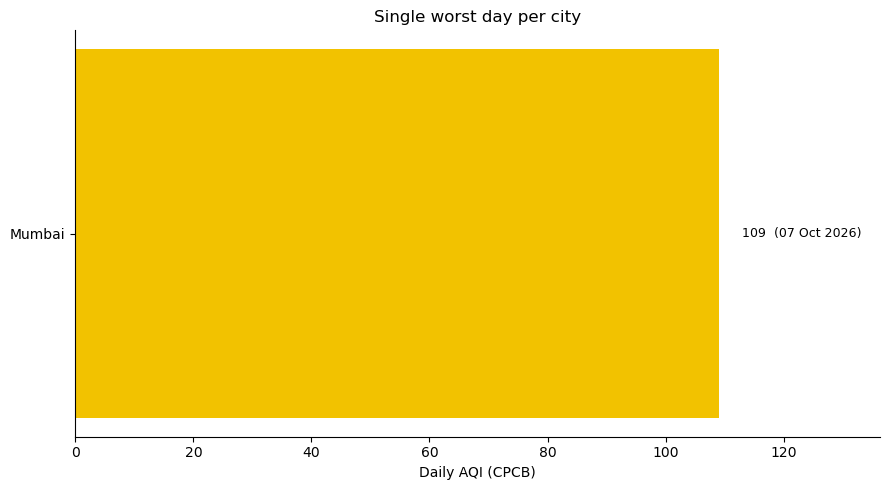

In [26]:
top = worst[worst.rank_in_city == 1]
if worst.empty:
    print("⚠ No daily AQI data yet - see the diagnostic cell above.")
else:
    top = worst[worst.rank_in_city == 1].sort_values("aqi")
    colors = {"Good": "#009966", "Satisfactory": "#7fbf3f", "Moderate": "#f2c200", "Poor": "#ff7e00",
              "Very Poor": "#cc0033", "Severe": "#7e0023"}
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top.city_name, top.aqi, color=[colors[c] for c in top.category])
    for y, (a, d) in enumerate(zip(top.aqi, top.obs_date)):
        ax.text(a + 4, y, f"{int(a)}  ({pd.Timestamp(d):%d %b %Y})", va="center", fontsize=9)
    ax.set_xlabel("Daily AQI (CPCB)"); ax.set_title("Single worst day per city"); ax.set_xlim(0, max(top.aqi) * 1.25)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

## 9 · Output 2 — Monthly averages

In [27]:
monthly = query_df("SELECT * FROM aqi.v_monthly_averages")
monthly.to_csv(r"C:\Users\Rucha Dhage\Desktop\Rucha\github\aqi_project_new\monthly_averages.csv", index=False)
monthly

,city_name,month,days_with_data,avg_aqi,max_aqi,avg_pm25,avg_pm10,avg_no2,unhealthy_days,pct_unhealthy_days,typical_category
0,Mumbai,2026-10-01,2,105.0,109.0,39.9,107.6,39.0,0,0.0,Moderate


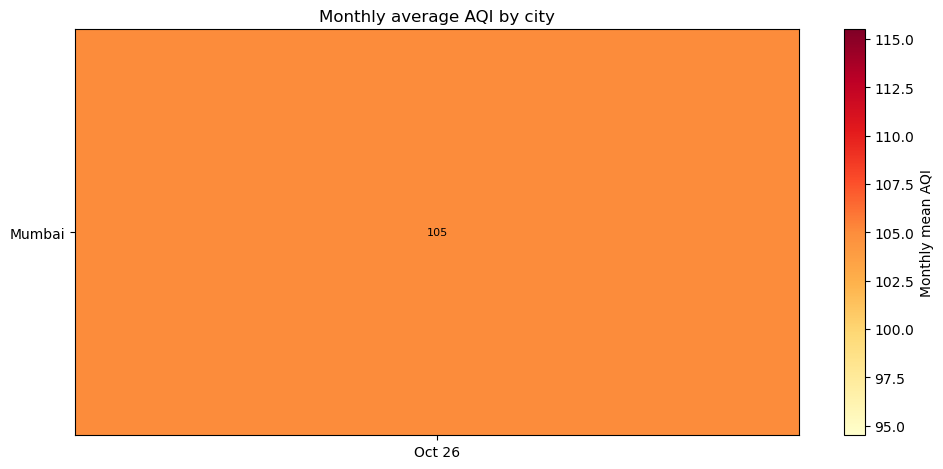

In [28]:
pivot = monthly.pivot
if monthly.empty:
    print("⚠ No monthly data yet - see the diagnostic cell above.")
else:
    pivot = monthly.pivot(index="city_name", columns="month", values="avg_aqi")
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    im = ax.imshow(pivot.values.astype(float), cmap="YlOrRd", aspect="auto")
    ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels([pd.Timestamp(m).strftime("%b %y") for m in pivot.columns])
    ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if pd.notna(v): ax.text(j, i, int(v), ha="center", va="center", fontsize=8)
    fig.colorbar(im, label="Monthly mean AQI"); ax.set_title("Monthly average AQI by city")
    plt.tight_layout(); plt.show()